# MLP Classifier on Fashion-MNIST

Trains the `784 → 256 → 64 → 10` classifier used by the generative-model
analysis. Checkpoint selection uses the validation split; the test split is
only used for the final evaluation and the feature artifacts required by
`08_classifier_analysis.ipynb`.


In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file()
    and (PROJECT_ROOT / "models" / "mlp_classifier.py").is_file()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: d:\Main\sem5\deep-learning\ASG_2


In [ ]:
import json
import time

import matplotlib.pyplot as plt
import torch
from torch import nn, optim

from data_loader import get_dataloaders
from models.mlp_classifier import build_mlp_classifier, extract_features
from utils.paths import (
    CHECKPOINT_DIR,
    DATA_DIR,
    FEATURES_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    ensure_results_dirs,
    get_device,
)
from utils.reproducibility import set_seed


In [8]:
SEED = 42
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001

DEVICE = get_device()
ensure_results_dirs()

print(f"Device: {DEVICE}")


Device: xpu


In [9]:
set_seed(SEED)

train_loader, val_loader, test_loader = get_dataloaders(
    root=DATA_DIR, batch_size=BATCH_SIZE, seed=SEED
)

print(f"Training samples: {len(train_loader.dataset)}")
print(f"Validation samples: {len(val_loader.dataset)}")
print(f"Testing samples: {len(test_loader.dataset)}")

images, labels = next(iter(train_loader))

print(f"Image shape: {images.shape}")
print(f"Label shape: {labels.shape}")


100%|██████████| 26.4M/26.4M [00:07<00:00, 3.68MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 142kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.55MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


Training samples: 56000
Validation samples: 7000
Testing samples: 7000
Image shape: torch.Size([128, 1, 28, 28])
Label shape: torch.Size([128])


## Model and optimizer


In [10]:
model = build_mlp_classifier().to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(model)


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=10, bias=True)
)


In [11]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)

            predictions = logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy


## Training


In [12]:
history = []

best_val_acc = 0.0
checkpoint_path = CHECKPOINT_DIR / "mlp_classifier_best.pth"

for epoch in range(EPOCHS):
    start_time = time.perf_counter()

    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)

    val_loss, val_acc = run_epoch(model, val_loader, criterion)

    epoch_time = time.perf_counter() - start_time

    history.append(
        {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "epoch_time": epoch_time,
        }
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save(model.state_dict(), checkpoint_path)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc * 100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc * 100:.2f}% "
        f"| Time: {epoch_time:.2f}s"
    )


Epoch [01/30] | Train Loss: 0.6033 | Train Acc: 78.90% | Val Loss: 0.4665 | Val Acc: 83.56% | Time: 19.69s
Epoch [02/30] | Train Loss: 0.4155 | Train Acc: 85.33% | Val Loss: 0.4011 | Val Acc: 85.56% | Time: 13.03s
Epoch [03/30] | Train Loss: 0.3671 | Train Acc: 86.87% | Val Loss: 0.3788 | Val Acc: 85.90% | Time: 12.74s
Epoch [04/30] | Train Loss: 0.3370 | Train Acc: 87.86% | Val Loss: 0.3559 | Val Acc: 86.97% | Time: 12.75s
Epoch [05/30] | Train Loss: 0.3161 | Train Acc: 88.43% | Val Loss: 0.3571 | Val Acc: 86.86% | Time: 12.54s
Epoch [06/30] | Train Loss: 0.3012 | Train Acc: 88.88% | Val Loss: 0.3364 | Val Acc: 87.97% | Time: 12.96s
Epoch [07/30] | Train Loss: 0.2865 | Train Acc: 89.48% | Val Loss: 0.3269 | Val Acc: 88.07% | Time: 13.68s
Epoch [08/30] | Train Loss: 0.2760 | Train Acc: 89.81% | Val Loss: 0.3312 | Val Acc: 87.73% | Time: 21.27s
Epoch [09/30] | Train Loss: 0.2628 | Train Acc: 90.28% | Val Loss: 0.3340 | Val Acc: 88.29% | Time: 21.53s
Epoch [10/30] | Train Loss: 0.2539 | 

## Test evaluation


In [14]:
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))

test_loss, test_acc = run_epoch(model, test_loader, criterion)

print("FINAL TEST RESULTS")

print(f"Best Validation Accuracy: {best_val_acc * 100:.2f}%")
print(f"Test Accuracy:            {test_acc * 100:.2f}%")
print(f"Test Loss:                {test_loss:.4f}")

if test_acc >= 0.88:
    print("Target accuracy >= 88%: ACHIEVED")
else:
    print("Target accuracy >= 88%: NOT ACHIEVED")


FINAL TEST RESULTS
Best Validation Accuracy: 89.76%
Test Accuracy:            89.34%
Test Loss:                0.3369
Target accuracy >= 88%: ACHIEVED


## Training curves


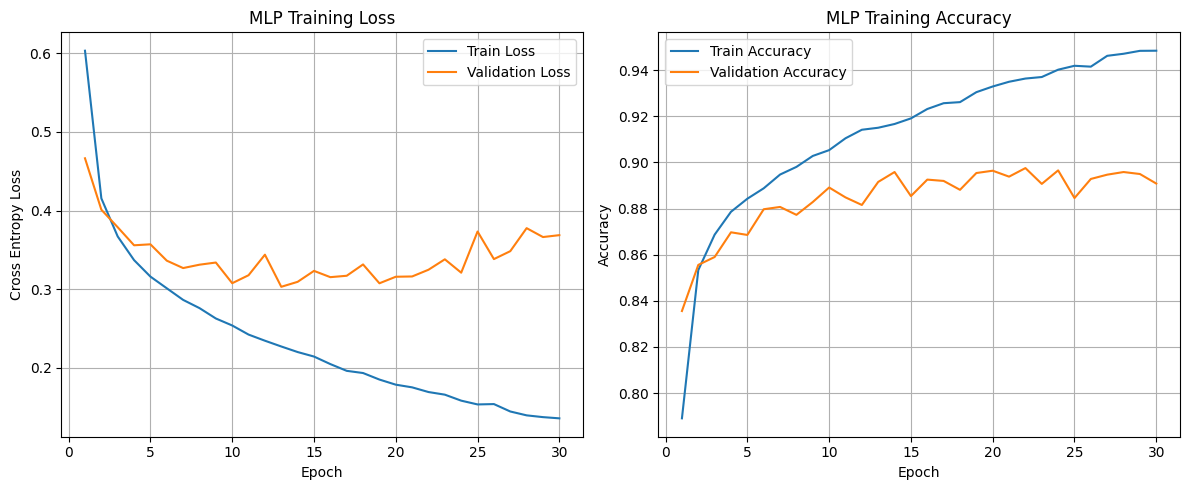

In [15]:
epochs = [item["epoch"] for item in history]

train_losses = [item["train_loss"] for item in history]
val_losses = [item["val_loss"] for item in history]

train_accs = [item["train_acc"] for item in history]
val_accs = [item["val_acc"] for item in history]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("MLP Training Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accs, label="Train Accuracy")
plt.plot(epochs, val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training Accuracy")
plt.legend()
plt.grid()

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "mlp_classifier_training_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [17]:
results = {
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "best_validation_accuracy": best_val_acc,
    "test_accuracy": test_acc,
    "test_loss": test_loss,
    "history": history,
}

with open(METRICS_DIR / "mlp_classifier.json", "w") as f:
    json.dump(results, f, indent=4)

print("Metrics saved successfully.")


Metrics saved successfully.


## Feature artifacts for notebook 08


In [18]:
FEATURE_DIR = FEATURES_DIR
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

model.eval()

# 1. Extract trained weights
weights = {
    "W1": model[1].weight.detach().cpu(),
    "W2": model[3].weight.detach().cpu(),
    "W3": model[5].weight.detach().cpu(),
    "b1": model[1].bias.detach().cpu(),
    "b2": model[3].bias.detach().cpu(),
    "b3": model[5].bias.detach().cpu(),
}

torch.save(weights, FEATURE_DIR / "mlp_weights.pth")


# 2. Extract latent features and original images
def extract_dataset_artifacts(loader):
    all_images = []
    all_labels = []
    all_features = []

    with torch.inference_mode():
        for images, labels in loader:
            images_device = images.to(DEVICE)

            features = extract_features(model, images_device)

            all_images.append(images.flatten(start_dim=1))

            all_labels.append(labels)
            all_features.append(features.cpu())

    return {
        "images": torch.cat(all_images),
        "labels": torch.cat(all_labels),
        "latent": torch.cat(all_features),
    }


train_artifacts = extract_dataset_artifacts(train_loader)
val_artifacts = extract_dataset_artifacts(val_loader)
test_artifacts = extract_dataset_artifacts(test_loader)


# 3. Save artifacts
torch.save(train_artifacts, FEATURE_DIR / "train_features.pt")
torch.save(val_artifacts, FEATURE_DIR / "val_features.pt")
torch.save(test_artifacts, FEATURE_DIR / "test_features.pt")


print("Artifacts saved successfully!")

print("W1:", weights["W1"].shape)
print("W2:", weights["W2"].shape)
print("W3:", weights["W3"].shape)

print("Train latent:", train_artifacts["latent"].shape)
print("Test latent:", test_artifacts["latent"].shape)


Artifacts saved successfully!
W1: torch.Size([256, 784])
W2: torch.Size([64, 256])
W3: torch.Size([10, 64])
Train latent: torch.Size([56000, 64])
Test latent: torch.Size([7000, 64])
